# 현실의 데이터 05: 광고 클릭률 (CTR) 예측

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/notebooks/datashop/05_ad_ctr.ipynb)

**분야**: 커머스 · 콘텐츠 &nbsp;|&nbsp; **이 분야에서 먼저 보는 문제**: 광고 랭킹 · 클릭률 (CTR) · 아주 큰 데이터

> 모바일 광고 노출 220만 번. 이 광고는 눌릴까?

**데이터**: Avazu CTR (원본 필드, 한 조각) (약 105MB). Avazu 모바일 광고 대회 (Kaggle 2014) 의 노출 기록 4,000만 줄 중 한 조각 220만 줄 (Hugging Face reczoo/Avazu_x4). 시각 · 광고 위치 · 사이트/앱 범주 · 기기 종류 등 (대부분 익명 해시).

인턴 · 산학협력 과제에서 처음 받게 될 데이터와 닮은 공개 데이터다. 데이터를 열어 보고, 아래 예시처럼 문제 하나를 정해 기준선과 비교한 뒤, 맨 끝의 **나의 다섯 칸** 을 채운다 (1주 2차시 '문제 정형화와 평가지표').

| 칸 | 이 노트북의 예시 |
|---|---|
| ① 한 행 | 광고 노출 한 번 |
| ② 입력 X | 시각 · 광고 위치 · 사이트/앱 범주 · 기기 · 광고 크기 … |
| ③ 출력 y | 눌렀나 (click) |
| ④ 평가지표 | 로그 손실 · ROC-AUC |
| ⑤ 기준선 | 모든 노출에 평균 클릭률 |

**논문 · 출처** (직접 열어 보자: 이 데이터를 누가, 왜, 어떻게 만들었나):
- [McMahan et al. (2013) Ad Click Prediction: a View from the Trenches, KDD](https://doi.org/10.1145/2487575.2488200)

In [1]:
import io, os, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def download(url, path):
    """Download url to path once (skip if it already exists)"""
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    if not os.path.exists(path):
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0 (ML course data shop)"})
        with urllib.request.urlopen(req, timeout=600) as r, open(path, "wb") as f:
            f.write(r.read())
    return path

## 입장: 데이터 받기

약 105MB. 처음엔 1~2분. 220만 줄 중 50만 줄만 쓴다.

In [2]:
URL = "https://huggingface.co/api/datasets/reczoo/Avazu_x4/parquet/default/train/0.parquet"
df = pd.read_parquet(download(URL, "data/avazu_x4_0.parquet")).sample(500000, random_state=0)
df["day"] = df["hour"] // 100 % 100; df["hod"] = df["hour"] % 100
print(df.shape, f"CTR {df['click'].mean():.1%}", "| days:", sorted(df["day"].unique()))
df.sample(5, random_state=0).T.head(16)

(500000, 26) CTR 17.4% | days: [np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(26)]


,364739,1156245,1800683,1390445,569520
id,10802519444535079058,15056685635802150350,9292090917870638828,9167071779636823059,2095090655123509416
click,0,1,0,0,0
hour,14102119,14102312,14102511,14102404,14102208
C1,1002,1002,1005,1005,1005
banner_pos,0,0,0,0,0
site_id,480eee51,4077d6f1,1fbe01fe,6ec06dbd,85f751fd
site_domain,5da2058a,c4e18dd6,f3845767,d262cf1e,c4e18dd6
site_category,50e219e0,50e219e0,28905ebd,f66779e6,50e219e0
app_id,ecad2386,ecad2386,ecad2386,ecad2386,a97b17d0
app_domain,7801e8d9,7801e8d9,7801e8d9,7801e8d9,aefc06bd


## 열어 보기

대부분의 열이 해시 (뜻을 알 수 없는 문자열) 다. 개인정보 · 영업 비밀 때문이다. 그래도 시각 · 광고 위치별 클릭률은 볼 수 있다.

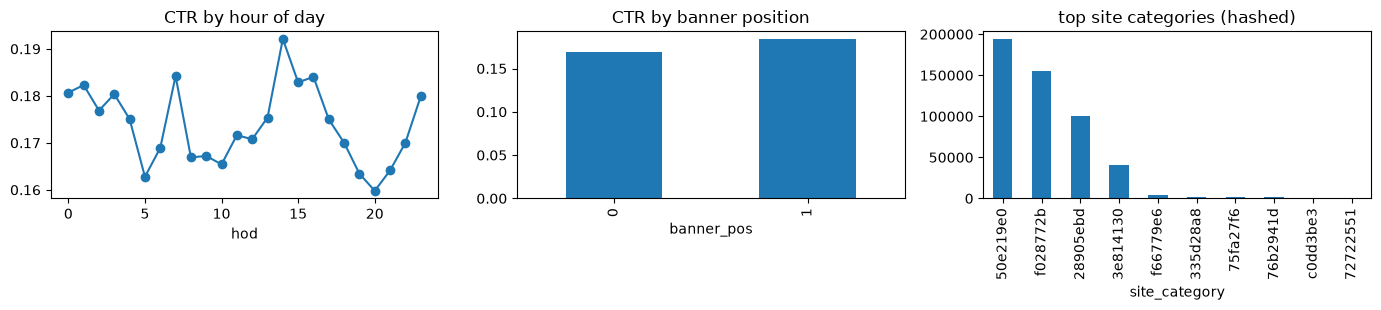

distinct values: {'site_id': 2178, 'app_id': 2396, 'device_model': 4488, 'device_ip': 297155}


In [3]:
fig, axs = plt.subplots(1, 3, figsize=(14, 3.2))
df.groupby("hod")["click"].mean().plot(ax=axs[0], marker="o", title="CTR by hour of day")
df.groupby("banner_pos")["click"].agg(["mean", "size"]).query("size > 500")["mean"].plot(kind="bar", ax=axs[1], title="CTR by banner position")
df["site_category"].value_counts().head(10).plot(kind="bar", ax=axs[2], title="top site categories (hashed)")
plt.tight_layout(); plt.show()
print("distinct values:", {c: df[c].nunique() for c in ["site_id", "app_id", "device_model", "device_ip"]})

## 문제 하나 골라 보기: 노출 → 클릭할까 (확률)

**날짜 순서**: 마지막 날 시험, 그 전 날들 학습. 범주마다 원-핫 (드문 값은 '기타' 로 묶는다) + 로지스틱회귀. 광고는 순서 (어떤 광고를 먼저 보여 줄까) 와 확률 (얼마를 받을까) 이 둘 다 중요해서 로그 손실과 AUC 를 같이 본다.

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import OneHotEncoder

def log_loss(y, p):
    p = np.clip(p, 1e-6, 1 - 1e-6); return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

cats = ["C1", "banner_pos", "site_id", "site_category", "app_id", "app_category", "device_model", "device_type", "device_conn_type",
        "C14", "C15", "C16", "C18", "C19", "C21", "hod"]
last = df["day"].max(); tr, te = df[df["day"] < last], df[df["day"] == last]
enc = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=100).fit(tr[cats].astype(str))
m = LogisticRegression(C=0.3, max_iter=1000).fit(enc.transform(tr[cats].astype(str)), tr["click"])
p = m.predict_proba(enc.transform(te[cats].astype(str)))[:, 1]
base = np.full(len(te), tr["click"].mean())
print(f"train {len(tr):,} rows, test (day {last}) {len(te):,} rows")
print(f"baseline (CTR {tr['click'].mean():.3f}): log loss {log_loss(te['click'].values, base):.4f}, ROC-AUC 0.5")
print(f"one-hot logistic          : log loss {log_loss(te['click'].values, p):.4f}, ROC-AUC {roc_auc_score(te['click'], p):.3f}")

train 455,325 rows, test (day 26) 44,675 rows
baseline (CTR 0.172): log loss 0.4868, ROC-AUC 0.5
one-hot logistic          : log loss 0.4352, ROC-AUC 0.722


**관찰**: 로그 손실이 조금 준 것도 실제 광고에서는 큰돈이다 (노출이 하루 수십억 번). 해시 열은 뜻을 몰라도 '자주 나오는 값' 이면 그대로 단서가 된다.

## 다른 문제로 바꿔 보기

- 같은 사람이 같은 광고를 열 번 봤다면? '피로도' 를 입력에 넣으려면 한 행이 '사람 × 광고 × 시각' 이어야 한다.
- 클릭이 아니라 **구매 (전환)** 를 맞히면 양성이 훨씬 드물어진다. 지표는?

### 나의 다섯 칸

아래 표를 직접 채워 보자. 위의 예시와 다르게 정해도 된다.

| 칸 | 내가 정한 것 |
|---|---|
| ① 한 행은 무엇? | |
| ② 입력 X (예측할 때 알 수 있는 것만) | |
| ③ 출력 y | |
| ④ 평가지표 | |
| ⑤ 기준선 | |